# Group Assignment 2
## Milestone 4: Banking Fraud Modeling, Evaluation and Data Generation Strategy

**Objective:** classify recorded banking transactions for fraud review using `fraud_flag` (1 = fraud, 0 = nonfraud). This is a supervised binary classification study, with an explicit check of whether the supplied risk scores make the result dependent on an upstream system.

**Input:** the supplied `banking_transactions.csv`. Dataset attribution: Deepesh Kansotia, [Banking Fraud Detection & Risk Analytics Dataset on Kaggle](https://www.kaggle.com/datasets/deepeshkansotia/banking-fraud-detection-and-risk-analytics-dataset/data). The supplied CSV is the authoritative input for the results here. Its collection process, currency, label-generation method and score lineage are not established by the file itself.

### Run in Google Colab

1. Open [Google Colab](https://colab.research.google.com/) and upload this `.ipynb` using **File → Upload notebook**.
2. Select **Runtime → Run all**. When prompted, upload the supplied `banking_transactions.csv`. You can instead place it in the Colab Files panel before running.
3. Use a CPU runtime. The notebook uses pandas, NumPy, SciPy, scikit-learn, Matplotlib and seaborn. It needs no Kaggle API key, GPU, external data download, or additional oversampling package.
4. Save/download the executed notebook for submission. The assignment requests **one `.ipynb` only**; its explanations, figures and one-page reflection are included here.

The saved outputs and result-specific markdown refer to the supplied file and configuration. A file fingerprint is checked below. If you change the CSV, split seed, features or search settings, rerun every cell and revise the saved interpretation and reflection to match the new outputs.


### Assignment coverage

| Assignment requirement | Implementation in this notebook |
|---|---|
| Part 1: experimental design and data preparation | Objective, feature availability audit, 60/20/20 split, five-fold training CV, fold-local preprocessing and reproducibility checks |
| Part 2: augmentation and imbalance | Training-only random oversampling; matched-fold comparison with the same model parameters; evaluation at original prevalence |
| Part 3: development and optimization | Dummy baseline, tuned logistic regression, random forest and histogram gradient boosting; an explicit final-selection rule |
| Part 4: evaluation and analytical depth | Precision, recall, F1, F2, ROC-AUC, AP and trapezoidal PR-AUC; confusion matrices, threshold sensitivity, uncertainty, ablations and error analysis |
| Part 5: analytical reflection | A structured, approximately one-page markdown reflection at the end, grounded in this notebook's measured results |

No earlier milestone notebook or instructor feedback was supplied. This notebook therefore states its assumptions and builds a complete reproducible workflow from the supplied CSV. It does not claim that unprovided feedback has been addressed.


In [1]:
# Configuration: keep these values fixed when reproducing the saved analysis.
import os
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')

from pathlib import Path
from io import BytesIO
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate, ParameterGrid
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, make_scorer, auc, brier_score_loss
)
from sklearn.utils.validation import check_is_fitted
from threadpoolctl import threadpool_limits

SEED = 2026
N_FOLDS = 5
AP_TOLERANCE = 0.005  # Predeclared practical tie / improvement tolerance, not a significance test.
N_BOOTSTRAPS = 1000
CSV_PATH = ''        # Optional: enter a specific local/Drive path, otherwise the upload flow is used.
EXPECTED_SHA256 = '7bbd26f45405c50c259e3ee719863eb599a950a6a449efc8286ec99d74e70141'
np.random.seed(SEED)
RUN_STARTED = time.perf_counter()

pd.set_option('display.max_columns', 24)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid', context='notebook', palette=['#167D9A', '#D55E45', '#D9A441'])
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

def show_figure(fig):
    """Embed a clean PNG in the notebook; also works outside an interactive GUI."""
    fig.tight_layout()
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=140, bbox_inches='tight', facecolor='white')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

versions = {'Python': platform.python_version(), 'pandas': pd.__version__,
            'NumPy': np.__version__, 'SciPy': scipy.__version__,
            'scikit-learn': sklearn.__version__, 'Matplotlib': matplotlib.__version__,
            'seaborn': sns.__version__}
display(pd.Series(versions, name='Version').to_frame())
print(f'Seed={SEED}; folds={N_FOLDS}; AP tolerance={AP_TOLERANCE}; bootstrap draws={N_BOOTSTRAPS}')


,Version
Python,3.12.14
pandas,2.2.3
NumPy,2.3.5
SciPy,1.17.0
scikit-learn,1.8.0
Matplotlib,3.10.8
seaborn,0.13.2


Seed=2026; folds=5; AP tolerance=0.005; bootstrap draws=1000


## Part 1. Experimental design and data preparation

### Objective, metrics and decision rules

The unit of analysis is one recorded transaction. The model ranks transactions by a fraud score and converts that score into a review flag. This notebook studies **retrospective transaction review**. It does not establish that all fields would be available for real-time payment authorization.

**Primary selection metric:** average precision (**AP**), a stepwise summary of the precision–recall curve. AP is useful here because the positive class is less common and we care about finding fraud without an unmanageable number of false alerts. We also report **trapezoidal PR-AUC**, which is a different numerical summary, and label the two separately. Accuracy is context only: predicting every transaction as nonfraud can score highly while finding no fraud. See [scikit-learn's AP definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

**Predeclared selection policy:** tune the three model families using mean five-fold training CV AP. Among families within 0.005 AP of the leader, prefer logistic regression, then gradient boosting, then random forest. This is a practical preference for a simpler near-tied model, not a statistical equivalence claim. Test random oversampling on that selected family's tuned parameters; retain it only if its mean CV AP improves by more than 0.005. These rules are fixed before any model evaluation below.

**Operating threshold:** after choosing the family and augmentation policy, maximize validation **F2**, where

\[
F_2 = \frac{5PR}{4P+R}.
\]

This gives recall more emphasis than precision. It is an explicit project assumption because actual investigation costs, missed-fraud losses and review capacity were not supplied. F2 does not encode a known monetary cost ratio. Report the associated precision, recall, false positives and alert rate so the trade-off is visible. Threshold ties favor the higher threshold. The final model remains fitted on training data; we do not refit after choosing the threshold.


In [2]:
if CSV_PATH:
    data_path = Path(CSV_PATH).expanduser()
    if not data_path.is_file():
        raise FileNotFoundError(f'CSV_PATH does not exist: {data_path}')
else:
    candidates = [Path('banking_transactions.csv'), Path('/content/banking_transactions.csv'),
                  Path('upload/banking_transactions.csv')]
    data_path = next((p for p in candidates if p.is_file()), None)
    if data_path is None:
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError('Place banking_transactions.csv beside the notebook, or set CSV_PATH.') from exc
        print('Upload the supplied banking_transactions.csv file.')
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith('.csv')]
        if len(csv_names) != 1:
            raise ValueError('Please upload exactly one CSV, banking_transactions.csv, and rerun this cell.')
        data_path = Path(csv_names[0])

file_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
raw_df = pd.read_csv(data_path)
print(f'Input: {data_path.name}; rows={len(raw_df):,}; columns={raw_df.shape[1]}')
print('SHA-256:', file_sha256)
if file_sha256 != EXPECTED_SHA256:
    warnings.warn('This file differs from the supplied CSV. Rerun all cells and update the saved markdown conclusions.')
display(raw_df.head(5))


Input: banking_transactions.csv; rows=10,000; columns=20
SHA-256: 7bbd26f45405c50c259e3ee719863eb599a950a6a449efc8286ec99d74e70141


,transaction_id,transaction_amount,login_attempts,device_risk_score,transfer_frequency,anomaly_score,account_age_days,transaction_time_hour,failed_transactions_last_30d,avg_monthly_balance,daily_transaction_count,geo_distance_km,session_duration_minutes,transaction_velocity_score,payment_channel,authentication_type,card_present_flag,international_transaction_flag,suspicious_ip_flag,fraud_flag
0,1000001,"17,829.0100",4,12.0000,13,0.3700,2354,22,25,"112,760.0700",63,3189,92,71.8000,POS Terminal,OTP,1,1,1,False
1,1000002,"16,401.8300",1,34.3000,17,0.2600,3181,17,15,"118,899.5200",83,839,63,11.8000,Web Banking,Biometric,0,0,1,False
2,1000003,"9,678.2900",8,67.8000,39,0.1500,1390,3,2,"408,168.9800",9,3938,80,35.7000,ATM,OTP,1,0,1,False
3,1000004,"19,013.3800",5,17.8000,42,0.5500,3716,16,6,"80,771.6900",78,11111,11,74.8000,Mobile App,OTP,1,1,0,False
4,1000005,"13,834.9500",3,88.9000,63,0.2400,4694,16,10,"382,265.3200",17,3171,87,0.0000,Mobile App,OTP,1,0,0,False


### Integrity checks and target definition

We validate the schema and target values, report missingness, and remove exact duplicate records before splitting so a repeated record cannot enter multiple partitions. Conflicting duplicate transaction IDs stop execution rather than being silently assigned a label. No row is discarded for being a large or unusual transaction; an extreme observation may be the event we need to detect.

`fraud_flag` is the only outcome. `transaction_id` is excluded from all model inputs and retained only to identify examples in error analysis. Imputation remains in the pipeline even if the current file has no missing values, so the handling strategy is explicit and fitted only where permitted.


In [3]:
TARGET = 'fraud_flag'
ID_COLUMN = 'transaction_id'
CATEGORICAL_COLUMNS = ['payment_channel', 'authentication_type']
FEATURE_COLUMNS = [
    'transaction_amount', 'login_attempts', 'device_risk_score', 'transfer_frequency',
    'anomaly_score', 'account_age_days', 'transaction_time_hour',
    'failed_transactions_last_30d', 'avg_monthly_balance', 'daily_transaction_count',
    'geo_distance_km', 'session_duration_minutes', 'transaction_velocity_score',
    'payment_channel', 'authentication_type', 'card_present_flag',
    'international_transaction_flag', 'suspicious_ip_flag'
]
required_columns = [ID_COLUMN, *FEATURE_COLUMNS, TARGET]
missing_columns = sorted(set(required_columns) - set(raw_df.columns))
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')

duplicate_rows = int(raw_df.duplicated().sum())
df = raw_df.drop_duplicates().copy()
if df[ID_COLUMN].isna().any() or not df[ID_COLUMN].is_unique:
    raise ValueError('Transaction IDs are missing or repeated after exact deduplication; investigate before splitting.')

target_text = df[TARGET].astype('string').str.strip().str.lower()
encoded_target = target_text.map({'false': 0, 'true': 1, '0': 0, '1': 1})
if encoded_target.isna().any():
    raise ValueError('fraud_flag must contain only nonmissing True/False or 0/1 values.')
df[TARGET] = encoded_target.astype('int64')
if set(df[TARGET].unique()) != {0, 1}:
    raise ValueError('Both target classes are needed for this classification experiment.')

numeric_raw = [c for c in FEATURE_COLUMNS if c not in CATEGORICAL_COLUMNS]
for column in numeric_raw:
    df[column] = pd.to_numeric(df[column], errors='raise')
    if np.isinf(df[column].to_numpy(dtype=float)).any():
        raise ValueError(f'Infinite values in {column}; investigate their source.')
    if (df[column].dropna() < 0).any():
        raise ValueError(f'Unexpected negative values in {column}; check the data dictionary.')
for column in CATEGORICAL_COLUMNS:
    df[column] = df[column].map(lambda v: v.strip() if isinstance(v, str) else v).replace('', np.nan)
for column in ['card_present_flag', 'international_transaction_flag', 'suspicious_ip_flag']:
    if not set(df[column].dropna().unique()).issubset({0, 1}):
        raise ValueError(f'{column} must be binary.')
if not df['transaction_time_hour'].dropna().between(0, 23).all():
    raise ValueError('transaction_time_hour must be between 0 and 23.')

df = df.reset_index(drop=True)
audit_table = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                            'unique_values': df.nunique(dropna=True)})
display(audit_table)
class_counts = df[TARGET].value_counts().sort_index()
display(pd.DataFrame({'class': ['Nonfraud (0)', 'Fraud (1)'],
                      'count': class_counts.to_numpy(),
                      'percentage': 100 * class_counts.to_numpy() / len(df)}))
print(f'Exact duplicates removed: {duplicate_rows}; unique IDs: {df[ID_COLUMN].nunique():,}')
print('Total missing predictor values:', int(df[FEATURE_COLUMNS].isna().sum().sum()))
print('Majority/minority ratio:', round(class_counts[0] / class_counts[1], 2))


,dtype,missing,unique_values
transaction_id,int64,0,10000
transaction_amount,float64,0,9981
login_attempts,int64,0,12
device_risk_score,float64,0,1001
transfer_frequency,int64,0,81
anomaly_score,float64,0,99
account_age_days,int64,0,4339
transaction_time_hour,int64,0,24
failed_transactions_last_30d,int64,0,26
avg_monthly_balance,float64,0,9997


,class,count,percentage
0,Nonfraud (0),8749,87.4900
1,Fraud (1),1251,12.5100


Exact duplicates removed: 0; unique IDs: 10,000
Total missing predictor values: 0
Majority/minority ratio: 6.99


### Feature set and leakage audit

All 18 non-ID, non-target fields are candidate inputs for the conditional, retrospective model. Their availability is a **source-data assumption**, not a fact established by successful cross-validation.

| Fields | Treatment and availability condition |
|---|---|
| `transaction_id` | Excluded: unique record identifier, not an explanatory customer feature |
| `fraud_flag` | Target only; never included in preprocessing or predictors |
| `transaction_amount`, `payment_channel`, `authentication_type`, `card_present_flag`, `international_transaction_flag` | Recorded transaction descriptors; currency and detailed category definitions are not supplied |
| `account_age_days`, `transaction_time_hour`, `geo_distance_km`, `login_attempts` | Context variables; require definitions consistent with the scoring moment |
| `avg_monthly_balance`, `daily_transaction_count`, `transfer_frequency`, `failed_transactions_last_30d` | Historical aggregates must use information available **as of** the transaction, not a later completed period |
| `session_duration_minutes` | May require the session to finish; this is one reason the objective is retrospective review |
| `anomaly_score`, `device_risk_score`, `transaction_velocity_score`, `suspicious_ip_flag` | Upstream scores/flags require lineage: how they were produced, when they were available, and whether labels or future information entered their calculation |

The preprocessing pipeline prevents leakage introduced by this notebook: splitting precedes feature–target EDA; medians, scaling and encoding are learned within each training fold; oversampling never touches a held-out fold; threshold tuning uses validation only. This follows the separation principle described in [scikit-learn's leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html).

It cannot remove leakage already embedded in an input column. We therefore run development-only ablations without `anomaly_score`, without all three numeric scores, and with `anomaly_score` alone. These diagnose dependence; they do not certify the remaining fields' timing or provenance.


### Validation strategy

Use a reproducible **60% training / 20% validation / 20% test** stratified split. Five stratified folds inside the training partition support parameter tuning and the oversampling comparison. Validation selects the operating threshold and supports diagnostics. The test partition is opened for predictions only after the fitted model and threshold are frozen.

There is no full date/time column and no customer/account identifier. `transaction_time_hour` describes an hour of day; it cannot support a chronological split. Transaction-level stratification therefore estimates generalization to comparable, exchangeable records in this dataset. It does not measure future-period performance or generalization to unseen customers. Unknown customer overlap may still make these results optimistic.


In [4]:
development_index, test_index = train_test_split(
    df.index.to_numpy(), test_size=0.20, random_state=SEED, stratify=df[TARGET]
)
train_index, valid_index = train_test_split(
    development_index, test_size=0.25, random_state=SEED + 1,
    stratify=df.loc[development_index, TARGET]
)

X_train, y_train = df.loc[train_index, FEATURE_COLUMNS].copy(), df.loc[train_index, TARGET].copy()
X_valid, y_valid = df.loc[valid_index, FEATURE_COLUMNS].copy(), df.loc[valid_index, TARGET].copy()
X_test, y_test = df.loc[test_index, FEATURE_COLUMNS].copy(), df.loc[test_index, TARGET].copy()

assert set(train_index).isdisjoint(valid_index)
assert set(train_index).isdisjoint(test_index)
assert set(valid_index).isdisjoint(test_index)
assert len(train_index) + len(valid_index) + len(test_index) == len(df)
assert TARGET not in FEATURE_COLUMNS and ID_COLUMN not in FEATURE_COLUMNS

split_summary = pd.DataFrame([
    {'partition': label, 'rows': len(y), 'fraud': int(y.sum()),
     'nonfraud': int((y == 0).sum()), 'fraud_rate': float(y.mean())}
    for label, y in [('Train', y_train), ('Validation', y_valid), ('Test', y_test)]
]).set_index('partition')
display(split_summary)
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + 2)
cv_splits = list(cv.split(X_train, y_train))
assert all(set(a).isdisjoint(b) for a, b in cv_splits)
print('Only test size and stratification counts are inspected here. Test predictions are deferred to Part 4.')


,rows,fraud,nonfraud,fraud_rate
partition,,,,
Train,6000,751,5249,0.1252
Validation,2000,250,1750,0.1250
Test,2000,250,1750,0.1250


Only test size and stratification counts are inspected here. Test predictions are deferred to Part 4.


### Training-only exploratory analysis

The plots below use the training partition. We inspect class imbalance, transaction size and the supplied anomaly score. The amount axis uses the CSV's unspecified monetary units. Numeric associations describe this sample; they do not establish causes of fraud or justify removing legitimate outliers.


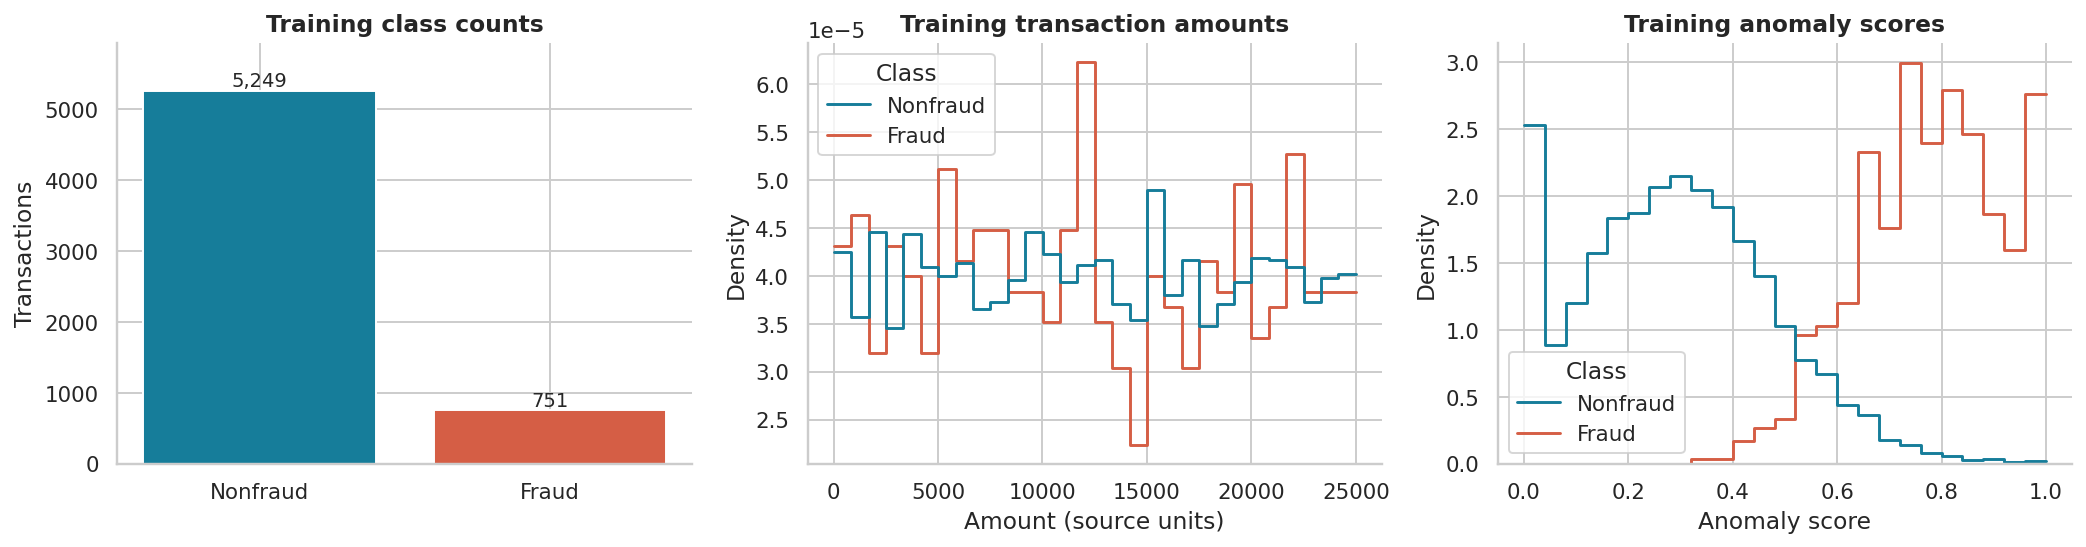

,Pearson correlation with fraud,absolute
anomaly_score,0.6717,0.6717
geo_distance_km,-0.0171,0.0171
daily_transaction_count,-0.0104,0.0104
account_age_days,-0.0096,0.0096
transfer_frequency,0.0086,0.0086
card_present_flag,-0.0069,0.0069
transaction_amount,-0.0055,0.0055
failed_transactions_last_30d,-0.0052,0.0052


,count,mean,min,max
fraud_label,,,,
Fraud,751,0.7718,0.3300,0.9900
Nonfraud,5249,0.2907,0.0100,0.9900


In [5]:
train_eda = X_train.assign(fraud_flag=y_train, fraud_label=y_train.map({0: 'Nonfraud', 1: 'Fraud'}))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
train_counts = y_train.value_counts().sort_index()
axes[0].bar(['Nonfraud', 'Fraud'], train_counts.to_numpy(), color=['#167D9A', '#D55E45'])
for i, count in enumerate(train_counts):
    axes[0].text(i, count + 65, f'{count:,}', ha='center')
axes[0].set(title='Training class counts', ylabel='Transactions', ylim=(0, train_counts.max() * 1.13))
sns.histplot(data=train_eda, x='transaction_amount', hue='fraud_label', bins=30,
             stat='density', common_norm=False, element='step', fill=False, ax=axes[1])
axes[1].set(title='Training transaction amounts', xlabel='Amount (source units)', ylabel='Density')
sns.histplot(data=train_eda, x='anomaly_score', hue='fraud_label', bins=np.linspace(0, 1, 26),
             stat='density', common_norm=False, element='step', fill=False, ax=axes[2])
axes[2].set(title='Training anomaly scores', xlabel='Anomaly score', ylabel='Density')
for ax in axes[1:]:
    ax.get_legend().set_title('Class')
show_figure(fig)

train_correlations = train_eda[numeric_raw + [TARGET]].corr()[TARGET].drop(TARGET)
display(train_correlations.rename('Pearson correlation with fraud').to_frame()
        .assign(absolute=lambda t: t.iloc[:, 0].abs()).sort_values('absolute', ascending=False).head(8))
display(train_eda.groupby('fraud_label')['anomaly_score'].agg(['count', 'mean', 'min', 'max']))


### Interpretation of the supplied data

The file contains **10,000 transactions and 20 columns**, with **1,251 fraud cases (12.51%)**. There are no missing predictor values and no exact duplicate records in this version. The training partition contains 751 fraud cases and 5,249 nonfraud cases, so the minority class is smaller but not represented by only a handful of records. A controlled oversampling experiment is justified; automatically declaring it necessary would go beyond the evidence.

The training correlation between `anomaly_score` and the binary target is **0.672**, and the training histogram shows much higher scores among fraud cases with overlap between classes. This is a reason to audit the score's origin and test its incremental value. It is not proof that the score is valid for deployment, proof of leakage, or a deterministic fraud rule. The amount distributions show substantial overlap, so amount alone does not visually separate the classes.

The input has no calendar timestamp or customer identifier. The split and claims therefore remain transaction-level. Imputers are defensive pipeline components, not a claim that missing values were found and repaired.


### Full preprocessing pipeline

1. Apply deterministic, row-level transformations: `log1p` to transaction amount, monthly balance and geographic distance; sine/cosine encoding of hour; and a log-transformed amount-to-balance ratio using a +1 denominator safeguard. These are modest hypotheses about scale and time-of-day continuity, not claimed improvements established by this experiment. They never inspect labels or other rows.
2. Impute numeric values with training-fold medians and categorical values with training-fold modes. The supplied file's observed missingness is reported above. `keep_empty_features=True` preserves an all-missing numeric feature if one occurs in a future training partition.
3. Standardize numeric features for logistic regression. Tree models use the same engineered variables without standardization because their splits do not require standardized units.
4. One-hot encode categories with `handle_unknown='ignore'`, using categories learned inside each training fold. Unseen categories are tolerated, but their all-zero encoding still represents a deployment limitation.
5. Fit the classifier, optionally duplicating minority training rows **after** fold-local preprocessing. Predictions never resample rows.

The fitted pipeline accepts raw predictor columns and performs the same transformations at inference. No clipping, target encoding, global feature selection or label-dependent feature construction is used.


In [6]:
def engineer_features(frame):
    """Stateless features. The conditional checks also support feature ablations."""
    result = frame.copy()
    # Keep categorical behavior consistent with both object and pandas StringDtype inputs.
    for column in CATEGORICAL_COLUMNS:
        if column in result:
            result[column] = result[column].astype(object).where(result[column].notna(), np.nan)
    if {'transaction_amount', 'avg_monthly_balance'}.issubset(result.columns):
        result['log_amount_to_balance'] = np.log1p(
            result['transaction_amount'] / (result['avg_monthly_balance'] + 1.0)
        )
    for column in ['transaction_amount', 'avg_monthly_balance', 'geo_distance_km']:
        if column in result:
            result[column] = np.log1p(result[column])
    if 'transaction_time_hour' in result:
        hour = result.pop('transaction_time_hour')
        result['hour_sin'] = np.sin(2 * np.pi * hour / 24)
        result['hour_cos'] = np.cos(2 * np.pi * hour / 24)
    return result

def build_pipeline(classifier, scale_numeric=False):
    numeric_steps = [('impute', SimpleImputer(strategy='median', keep_empty_features=True))]
    if scale_numeric:
        numeric_steps.append(('scale', StandardScaler()))
    categorical_steps = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    preprocess = ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), make_column_selector(dtype_include=np.number)),
        ('categorical', categorical_steps, make_column_selector(dtype_include=object))
    ], remainder='drop', sparse_threshold=0)
    return Pipeline([
        ('features', FunctionTransformer(engineer_features, validate=False)),
        ('preprocess', preprocess),
        ('model', classifier)
    ])

scoring = {'ap': 'average_precision', 'roc_auc': 'roc_auc',
           'f2': make_scorer(fbeta_score, beta=2, zero_division=0)}
print('Raw feature count:', len(FEATURE_COLUMNS))
print('Engineered feature count before one-hot encoding:', engineer_features(X_train.head(2)).shape[1])


Raw feature count: 18
Engineered feature count before one-hot encoding: 20


## Part 2. Data generation and imbalance strategy

The class distribution warrants an imbalance experiment, but the presence of more than a thousand labelled fraud examples does not by itself prove that augmentation is necessary. We compare unaugmented training with **random oversampling to a 1:1 training balance**. Oversampling duplicates existing minority rows; it does not create independent evidence or discover new fraud patterns.

Random duplication preserves valid categorical and binary combinations. It is a transparent choice for this mixed data; unconstrained interpolation after one-hot encoding could produce implausible synthetic records. The method follows [random oversampling with replacement](https://imbalanced-learn.org/stable/over_sampling.html), implemented here in a small scikit-learn-compatible wrapper so no additional package is needed.

The wrapper's `fit` method is called **inside the training fold**. It samples only the already-transformed training rows, retains every original row, and adds minority duplicates until both classes have the majority count. Preprocessing is fitted on the original fold before duplication. Validation folds, the validation partition and test partition keep their original prevalence. The controlled before/after experiment runs after hyperparameter tuning so both variants share the same underlying classifier settings and folds.

**Risks:** repeated minority cases can be memorized; rare but erroneous labels get amplified; a 50% training fraud rate distorts probability interpretation; duplication cannot address missing fraud mechanisms or label bias. A recall increase at threshold 0.5 alone is not evidence of better ranking or generalization. We compare AP, Brier score and operating-point metrics at original prevalence.


In [7]:
class TrainingOnlyRandomOversampler(ClassifierMixin, BaseEstimator):
    """Random oversampling inside fit; predict methods never alter the sample count."""
    def __init__(self, estimator, random_state=SEED):
        self.estimator = estimator
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        classes, counts = np.unique(y, return_counts=True)
        if len(classes) != 2:
            raise ValueError('This experiment expects two classes in every training fold.')
        rng = np.random.default_rng(self.random_state)
        sampled_indices = [np.arange(len(y))]
        for label, count in zip(classes, counts):
            extra = int(counts.max() - count)
            if extra:
                sampled_indices.append(rng.choice(np.flatnonzero(y == label), size=extra, replace=True))
        sampled_indices = np.concatenate(sampled_indices)
        rng.shuffle(sampled_indices)
        self.class_counts_before_ = dict(zip(classes.tolist(), counts.tolist()))
        self.class_counts_after_ = {int(label): int((y[sampled_indices] == label).sum()) for label in classes}
        self.n_original_samples_ = len(y)
        self.n_resampled_samples_ = len(sampled_indices)
        self.n_features_in_ = X.shape[1]
        self.estimator_ = clone(self.estimator).fit(X[sampled_indices], y[sampled_indices])
        self.classes_ = self.estimator_.classes_
        return self

    def predict_proba(self, X):
        check_is_fitted(self, 'estimator_')
        return self.estimator_.predict_proba(X)

    def predict(self, X):
        check_is_fitted(self, 'estimator_')
        return self.estimator_.predict(X)

print('The sampler has been defined, but no data has been resampled yet.')


The sampler has been defined, but no data has been resampled yet.


## Part 3. Final model development and optimization

### Candidate models and assumptions

| Model | Why include it? | Main assumptions, failure modes and trade-offs |
|---|---|---|
| Dummy prevalence baseline | Predicts the training fraud prevalence for every row; measures whether learned ranking adds value | At threshold 0.5 it predicts only the majority class. Its accuracy can be misleading, and its AP equals evaluation prevalence |
| Logistic regression | Regularized, compact and easier to explain; a useful check against unnecessary complexity | Linear log-odds in the engineered inputs; can miss interactions and nonlinear thresholds. Correlated inputs complicate coefficient interpretation |
| Random forest | Learns nonlinear splits and interactions without a linear decision boundary | Deep trees can memorize sparse cases and duplicates; larger model, less direct interpretation; limited extrapolation |
| Histogram gradient boosting | Sequentially learns nonlinear patterns with controlled leaf complexity | Can fit noise or unstable patterns; results depend on learning rate, tree complexity and regularization; upstream-score dependence can still dominate |

The search varies logistic regularization (`C`), forest depth/minimum leaf size, and boosting learning rate/leaf count/L2 regularization. Forest size and boosting iteration count are fixed to bound CPU cost. This is a compact, documented search, not a claim to have found the globally optimal model. Five-fold CV scores are used for selection; their best-candidate values are mildly optimistic because they also drove tuning. The final untouched test estimate is the main evaluation of the completed procedure.


In [8]:
model_specs = {
    'Logistic regression': (
        build_pipeline(LogisticRegression(max_iter=2000, solver='lbfgs', random_state=SEED), True),
        {'model__C': [0.1, 1.0, 10.0]}
    ),
    'Random forest': (
        build_pipeline(RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=SEED)),
        {'model__max_depth': [5, 12, None], 'model__min_samples_leaf': [2, 10]}
    ),
    'Histogram gradient boosting': (
        build_pipeline(HistGradientBoostingClassifier(max_iter=150, early_stopping=False, random_state=SEED)),
        {'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [7, 15],
         'model__l2_regularization': [1.0, 10.0]}
    )
}

searches, tuned_models, fold_scores, tuning_rows = {}, {}, {}, []
for name, (pipeline, grid) in model_specs.items():
    print(f'Tuning {name}: {len(ParameterGrid(grid))} settings x {N_FOLDS} folds', flush=True)
    search = GridSearchCV(pipeline, grid, scoring=scoring, refit='ap', cv=cv_splits,
                          n_jobs=1, return_train_score=True, error_score='raise')
    with threadpool_limits(limits=2):
        search.fit(X_train, y_train)
    searches[name], tuned_models[name] = search, search.best_estimator_
    best = search.best_index_
    scores = np.array([search.cv_results_[f'split{i}_test_ap'][best] for i in range(N_FOLDS)])
    fold_scores[name] = scores
    tuning_rows.append({
        'model': name, 'cv_ap_mean': scores.mean(), 'cv_ap_sd': scores.std(ddof=1),
        'cv_train_ap': search.cv_results_['mean_train_ap'][best],
        'cv_roc_auc': search.cv_results_['mean_test_roc_auc'][best],
        'cv_f2_at_0.5': search.cv_results_['mean_test_f2'][best],
        'mean_fit_seconds': search.cv_results_['mean_fit_time'][best],
        'parameters': search.best_params_
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values('cv_ap_mean', ascending=False).reset_index(drop=True)
display(tuning_results.drop(columns='parameters'))
display(tuning_results[['model', 'parameters']])

family_priority = ['Logistic regression', 'Histogram gradient boosting', 'Random forest']
top_cv_ap = tuning_results['cv_ap_mean'].max()
eligible_families = set(tuning_results.loc[tuning_results['cv_ap_mean'] >= top_cv_ap - AP_TOLERANCE, 'model'])
baseline_name = next(name for name in family_priority if name in eligible_families)
baseline_model = tuned_models[baseline_name]
print('Family selected by the predeclared CV/tie rule:', baseline_name)

dummy_model = build_pipeline(DummyClassifier(strategy='prior'))
dummy_model.fit(X_train, y_train)


Tuning Logistic regression: 3 settings x 5 folds
Tuning Random forest: 6 settings x 5 folds
Tuning Histogram gradient boosting: 8 settings x 5 folds


,model,cv_ap_mean,cv_ap_sd,cv_train_ap,cv_roc_auc,cv_f2_at_0.5,mean_fit_seconds
0,Logistic regression,0.8582,0.0186,0.8663,0.9766,0.7485,0.0320
1,Histogram gradient boosting,0.8477,0.0163,0.9179,0.9757,0.7768,0.1306
2,Random forest,0.8370,0.0077,0.9505,0.9685,0.7782,1.9246


,model,parameters
0,Logistic regression,{'model__C': 0.1}
1,Histogram gradient boosting,"{'model__l2_regularization': 10.0, 'model__learning_rate': 0.05, 'model__max_leaf_node..."
2,Random forest,"{'model__max_depth': 12, 'model__min_samples_leaf': 10}"


Family selected by the predeclared CV/tie rule: Logistic regression


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function eng...x7f10f8477420>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to

,Logistic regression,Random forest,Histogram gradient boosting
Fold,,,
1,0.8612,0.8315,0.8511
2,0.8610,0.8470,0.8722
3,0.8708,0.8289,0.8429
4,0.8719,0.8428,0.8454
5,0.8263,0.8348,0.8271


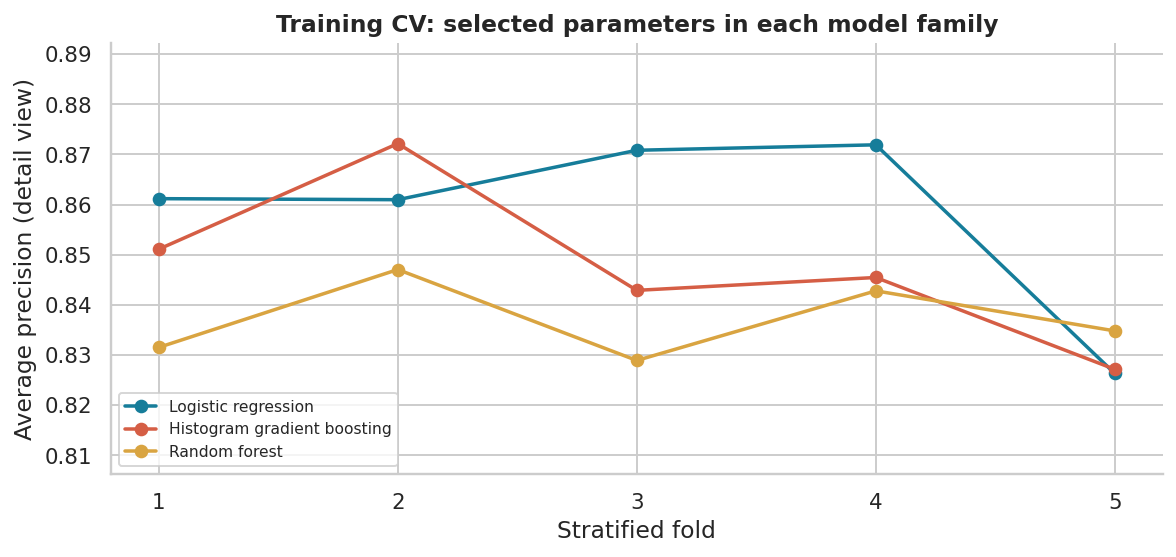

Fold standard deviations describe split sensitivity; correlated CV folds are not independent replications.


In [9]:
fold_table = pd.DataFrame(fold_scores, index=pd.Index(range(1, N_FOLDS + 1), name='Fold'))
display(fold_table)
fig, ax = plt.subplots(figsize=(8.5, 4.1))
for name in family_priority:
    ax.plot(fold_table.index, fold_table[name], marker='o', linewidth=1.8, label=name)
ax.set(title='Training CV: selected parameters in each model family', xlabel='Stratified fold',
       ylabel='Average precision (detail view)', xticks=list(fold_table.index),
       ylim=(max(0, fold_table.to_numpy().min() - 0.02), min(1, fold_table.to_numpy().max() + 0.02)))
ax.legend(loc='lower left', fontsize=8)
show_figure(fig)
print('Fold standard deviations describe split sensitivity; correlated CV folds are not independent replications.')


### Controlled augmentation experiment (Part 2 results)

Hold the selected family's classifier parameters, feature pipeline and five CV splits fixed. The only change is minority-row duplication inside `fit`. AP measures ranking without selecting a threshold. We also compare the two variants on validation at 0.5 and under the same validation-F2 threshold rule. This separates a change in the score scale from an improvement in ranking.

The AP gain required to retain oversampling is the predeclared 0.005. Fold differences are descriptive, not a formal significance test. The augmented variant is not given a second hyperparameter search; the comparison isolates augmentation at the selected baseline settings, so it does not rule out every other resampling strategy or ratio.


In [10]:
oversampled_model = clone(baseline_model)
oversampled_model.set_params(model=TrainingOnlyRandomOversampler(
    estimator=clone(baseline_model.named_steps['model']), random_state=SEED + 3
))
with threadpool_limits(limits=2):
    augmented_cv = cross_validate(oversampled_model, X_train, y_train, cv=cv_splits,
                                  scoring=scoring, return_train_score=True,
                                  n_jobs=1, error_score='raise')
    oversampled_model.fit(X_train, y_train)

augmentation_fold_results = pd.DataFrame({
    'fold': np.arange(1, N_FOLDS + 1),
    'without_oversampling_ap': fold_scores[baseline_name],
    'with_oversampling_ap': augmented_cv['test_ap']
})
augmentation_fold_results['ap_change'] = (
    augmentation_fold_results['with_oversampling_ap'] - augmentation_fold_results['without_oversampling_ap']
)
display(augmentation_fold_results.set_index('fold'))
augmentation_delta = float(augmentation_fold_results['ap_change'].mean())
use_oversampling = augmentation_delta > AP_TOLERANCE
final_model = oversampled_model if use_oversampling else baseline_model
final_name = baseline_name + (' + random oversampling' if use_oversampling else ' (no oversampling)')
final_cv_scores = augmented_cv['test_ap'] if use_oversampling else fold_scores[baseline_name]

sampler = oversampled_model.named_steps['model']
display(pd.DataFrame({'before': sampler.class_counts_before_, 'after': sampler.class_counts_after_})
        .rename_axis('Class'))
assert sampler.n_original_samples_ == len(X_train)
assert sampler.class_counts_after_[0] == sampler.class_counts_after_[1]
assert oversampled_model.predict_proba(X_valid).shape[0] == len(X_valid)
print(f'Mean paired CV AP change: {augmentation_delta:+.6f}')
print(f'Oversampling retained: {use_oversampling}. Selected fitted model: {final_name}')


,without_oversampling_ap,with_oversampling_ap,ap_change
fold,,,
1,0.8612,0.8590,-0.0022
2,0.8610,0.8610,-0.0000
3,0.8708,0.8655,-0.0053
4,0.8719,0.8712,-0.0007
5,0.8263,0.8209,-0.0054


,before,after
Class,,
0,5249,5249
1,751,5249


Mean paired CV AP change: -0.002732
Oversampling retained: False. Selected fitted model: Logistic regression (no oversampling)


### Validation comparisons and threshold selection

Model-family and augmentation choices are now fixed using training CV. The next table evaluates the candidates at a common threshold of 0.5 on validation. Each model's AP, ROC-AUC and Brier score use its continuous predictions. Lower Brier score means smaller squared probability error, although class prevalence affects its scale. An oversampled classifier's raw outputs should not be assumed to be calibrated fraud probabilities.

We then select the final operating threshold on validation only. Separating model fitting from threshold tuning follows [scikit-learn's threshold-selection guidance](https://scikit-learn.org/stable/modules/classification_threshold.html). The final test labels never participate in this decision.


In [11]:
def evaluate_scores(y_true, probabilities, threshold):
    y_array = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    predicted = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_array, predicted, labels=[0, 1]).ravel()
    precision_curve, recall_curve, _ = precision_recall_curve(y_array, probabilities)
    return {
        'accuracy': accuracy_score(y_array, predicted),
        'precision': precision_score(y_array, predicted, zero_division=0),
        'recall': recall_score(y_array, predicted, zero_division=0),
        'f1': f1_score(y_array, predicted, zero_division=0),
        'f2': fbeta_score(y_array, predicted, beta=2, zero_division=0),
        'roc_auc': roc_auc_score(y_array, probabilities),
        'average_precision': average_precision_score(y_array, probabilities),
        'pr_auc_trapezoid': auc(recall_curve[::-1], precision_curve[::-1]),
        'brier': brier_score_loss(y_array, probabilities),
        'alert_rate': predicted.mean(),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)
    }

def select_f2_threshold(y_true, probabilities):
    precisions, recalls, thresholds = precision_recall_curve(y_true, probabilities)
    denom = 4 * precisions[:-1] + recalls[:-1]
    f2_values = np.divide(5 * precisions[:-1] * recalls[:-1], denom,
                          out=np.zeros_like(denom), where=denom > 0)
    tied_best = np.flatnonzero(np.isclose(f2_values, f2_values.max(), rtol=0, atol=1e-12))
    return float(thresholds[tied_best[-1]])  # Thresholds are sorted; higher threshold breaks ties.

validation_probabilities = {name: model.predict_proba(X_valid)[:, 1] for name, model in tuned_models.items()}
validation_probabilities['Selected family + oversampling'] = oversampled_model.predict_proba(X_valid)[:, 1]
validation_probabilities['Dummy prevalence'] = dummy_model.predict_proba(X_valid)[:, 1]
validation_rows = []
for name, probabilities in validation_probabilities.items():
    validation_rows.append({'model': name, **evaluate_scores(y_valid, probabilities, 0.5)})
validation_results = pd.DataFrame(validation_rows).set_index('model')
display(validation_results[['average_precision', 'roc_auc', 'precision', 'recall', 'f1', 'f2', 'brier', 'alert_rate']])

augmentation_validation_rows = []
for variant, fitted in [('No oversampling', baseline_model), ('Random oversampling', oversampled_model)]:
    probabilities = fitted.predict_proba(X_valid)[:, 1]
    for policy, threshold in [('Default 0.5', 0.5), ('Validation max F2', select_f2_threshold(y_valid, probabilities))]:
        augmentation_validation_rows.append({
            'variant': variant, 'policy': policy, 'threshold': threshold,
            **evaluate_scores(y_valid, probabilities, threshold)
        })
augmentation_validation = pd.DataFrame(augmentation_validation_rows)
display(augmentation_validation[['variant', 'policy', 'threshold', 'average_precision',
                                 'precision', 'recall', 'f2', 'brier', 'alert_rate']])

valid_probabilities = final_model.predict_proba(X_valid)[:, 1]
final_threshold = select_f2_threshold(y_valid, valid_probabilities)
validation_at_threshold = evaluate_scores(y_valid, valid_probabilities, final_threshold)
print(f'Frozen family/augmentation: {final_name}')
print(f'Validation-selected F2 threshold: {final_threshold:.6f}')
display(pd.Series(validation_at_threshold, name='Validation at chosen threshold').to_frame())


,average_precision,roc_auc,precision,recall,f1,f2,brier,alert_rate
model,,,,,,,,
Logistic regression,0.8202,0.9714,0.7904,0.7240,0.7557,0.7364,0.0412,0.1145
Random forest,0.8277,0.9645,0.7778,0.7840,0.7809,0.7827,0.0424,0.1260
Histogram gradient boosting,0.8177,0.9722,0.7928,0.7960,0.7944,0.7954,0.0407,0.1255
Selected family + oversampling,0.8222,0.9713,0.6170,0.9280,0.7412,0.8430,0.0618,0.1880
Dummy prevalence,0.1250,0.5000,0.0000,0.0000,0.0000,0.0000,0.1094,0.0000


,variant,policy,threshold,average_precision,precision,recall,f2,brier,alert_rate
0,No oversampling,Default 0.5,0.5000,0.8202,0.7904,0.7240,0.7364,0.0412,0.1145
1,No oversampling,Validation max F2,0.2086,0.8202,0.6921,0.9080,0.8547,0.0412,0.1640
2,Random oversampling,Default 0.5,0.5000,0.8222,0.6170,0.9280,0.8430,0.0618,0.1880
3,Random oversampling,Validation max F2,0.6498,0.8222,0.6963,0.9080,0.8560,0.0618,0.1630


Frozen family/augmentation: Logistic regression (no oversampling)
Validation-selected F2 threshold: 0.208594


,Validation at chosen threshold
accuracy,0.9380
precision,0.6921
recall,0.9080
f1,0.7855
f2,0.8547
roc_auc,0.9714
average_precision,0.8202
pr_auc_trapezoid,0.8194
brier,0.0412
alert_rate,0.1640


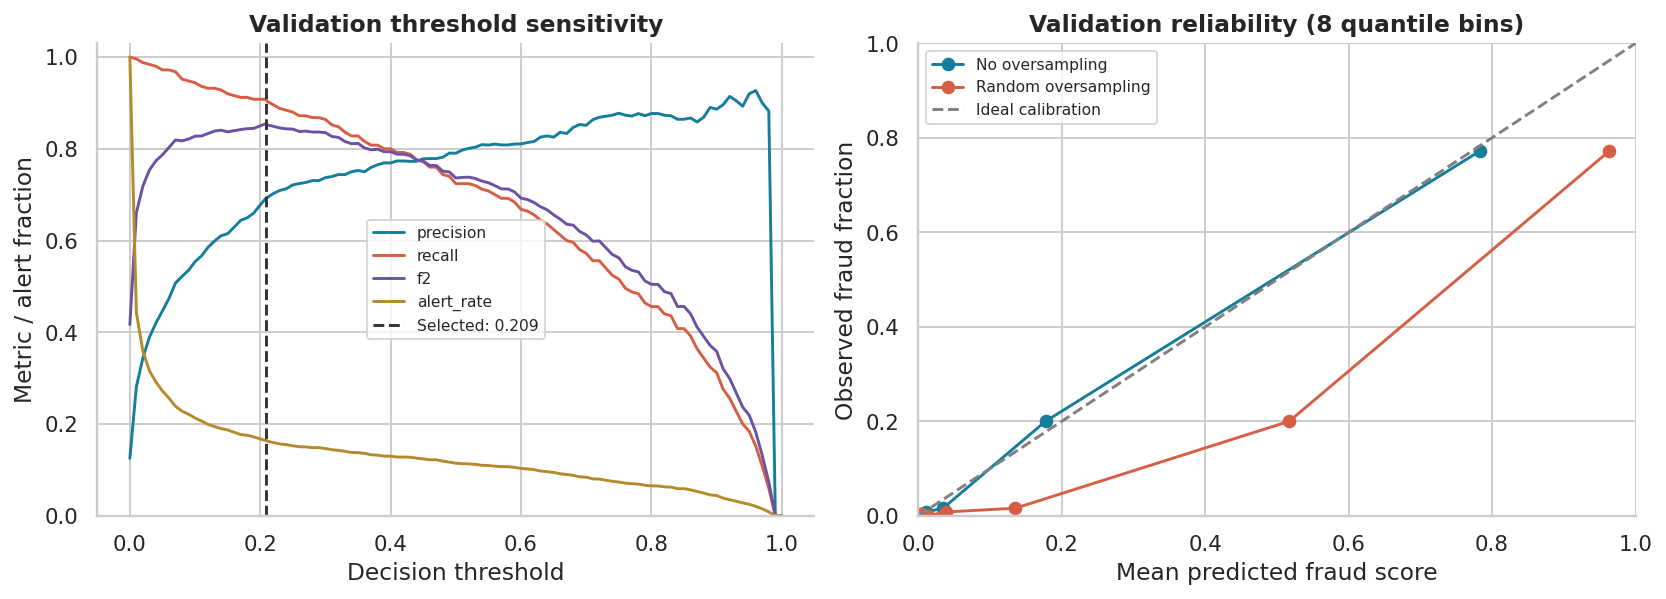

,threshold,precision,recall,f2,fp,fn,alert_rate
0,0.1586,0.6250,0.9200,0.8406,138,20,0.1840
1,0.2086,0.6921,0.9080,0.8547,101,23,0.1640
2,0.2586,0.7228,0.8760,0.8404,84,31,0.1515
3,0.5000,0.7904,0.7240,0.7364,48,69,0.1145


In [12]:
threshold_grid = np.unique(np.r_[np.linspace(0, 1, 101), final_threshold])
threshold_sensitivity = pd.DataFrame([
    {'threshold': threshold, **evaluate_scores(y_valid, valid_probabilities, threshold)}
    for threshold in threshold_grid
])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for metric, color in [('precision', '#167D9A'), ('recall', '#D55E45'), ('f2', '#6C52A3'), ('alert_rate', '#B38A2C')]:
    axes[0].plot(threshold_sensitivity['threshold'], threshold_sensitivity[metric], label=metric, color=color)
axes[0].axvline(final_threshold, color='#333333', linestyle='--', label=f'Selected: {final_threshold:.3f}')
axes[0].set(title='Validation threshold sensitivity', xlabel='Decision threshold', ylabel='Metric / alert fraction', ylim=(0, 1.03))
axes[0].legend(fontsize=8)
for label, fitted in [('No oversampling', baseline_model), ('Random oversampling', oversampled_model)]:
    probabilities = fitted.predict_proba(X_valid)[:, 1]
    observed, predicted = calibration_curve(y_valid, probabilities, n_bins=8, strategy='quantile')
    axes[1].plot(predicted, observed, marker='o', label=label)
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Ideal calibration')
axes[1].set(title='Validation reliability (8 quantile bins)', xlabel='Mean predicted fraud score',
            ylabel='Observed fraud fraction', xlim=(0, 1), ylim=(0, 1))
axes[1].legend(fontsize=8)
show_figure(fig)

nearby_thresholds = np.unique(np.clip([final_threshold - 0.05, final_threshold, final_threshold + 0.05, 0.5], 0, 1))
display(pd.DataFrame([{'threshold': t, **evaluate_scores(y_valid, valid_probabilities, t)} for t in nearby_thresholds])
        [['threshold', 'precision', 'recall', 'f2', 'fp', 'fn', 'alert_rate']])


### Model selection, bias–variance evidence and augmentation findings

**Selected family:** logistic regression with **C = 0.1**, without oversampling. Its mean CV AP is **0.8582** (fold SD **0.0186**), ahead of histogram gradient boosting (**0.8477**) and random forest (**0.8370**). The simpler model wins on the primary metric, so the ensemble complexity is not supported by this search.

The fold-level training/CV AP gaps support that decision. Logistic regression averages **0.8663** on fold-training rows versus **0.8582** on held-out folds. The corresponding figures are **0.9179 / 0.8477** for boosting and **0.9505 / 0.8370** for the forest. The larger ensemble gaps are consistent with higher variance at the selected settings. They do not decompose irreducible error or prove that more data would remove the gap. Logistic regression's small CV gap gives little evidence of severe training memorization, while its linear form can still miss useful interactions.

**Oversampling was not retained.** Its mean CV AP is **0.8555**, a paired change of **-0.0027**; all five fold changes are negative. Validation AP increases slightly from **0.8202** to **0.8222**, but that small split-specific difference does not override the predeclared CV policy. At threshold 0.5, oversampling raises validation recall from **72.4%** to **92.8%**, while false positives rise from **48** to **144**. After applying the same threshold-selection procedure, both variants reach **90.8%** recall and nearly identical F2 (**0.8547** versus **0.8560**). This indicates that much of the default-threshold recall change can be obtained by adjusting the unaugmented model's threshold. The oversampled variant also has worse validation Brier score (**0.0618** versus **0.0412**), consistent with its shifted training prevalence.

The final threshold is **0.208594**, chosen only on validation. It flags **328 of 2,000** validation transactions, with precision **69.2%** and recall **90.8%**. Its F2 objective is a project preference, not a validated investigation-capacity or cost constraint.


### Structural sensitivity: dependence on supplied scores

Use the chosen model family, parameters and augmentation policy for all four feature sets. Reduced-feature models are refitted within the same training CV folds and on training only for validation evaluation. Their parameters are **not retuned**; the comparison diagnoses sensitivity at the selected settings, rather than finding the best possible model for every subset. No ablation result changes the frozen final choice.

The anomaly-only model is a useful compact benchmark. If it nearly matches the full model, the added behavioral inputs have little demonstrated incremental ranking value at these settings. If removing scores collapses AP toward prevalence, performance is conditional on those supplied signals. Neither pattern proves that the score leaked labels: its generating process is unverified.


,feature_set,raw_features,cv_ap_mean,cv_ap_sd,validation_ap,validation_roc_auc
0,All candidate features,18,0.8582,0.0186,0.8202,0.9714
1,Without anomaly_score,17,0.1137,0.0079,0.1180,0.4836
2,Without three numeric scores,15,0.1152,0.0093,0.1172,0.4791
3,Anomaly score only,1,0.8561,0.0169,0.8234,0.9722


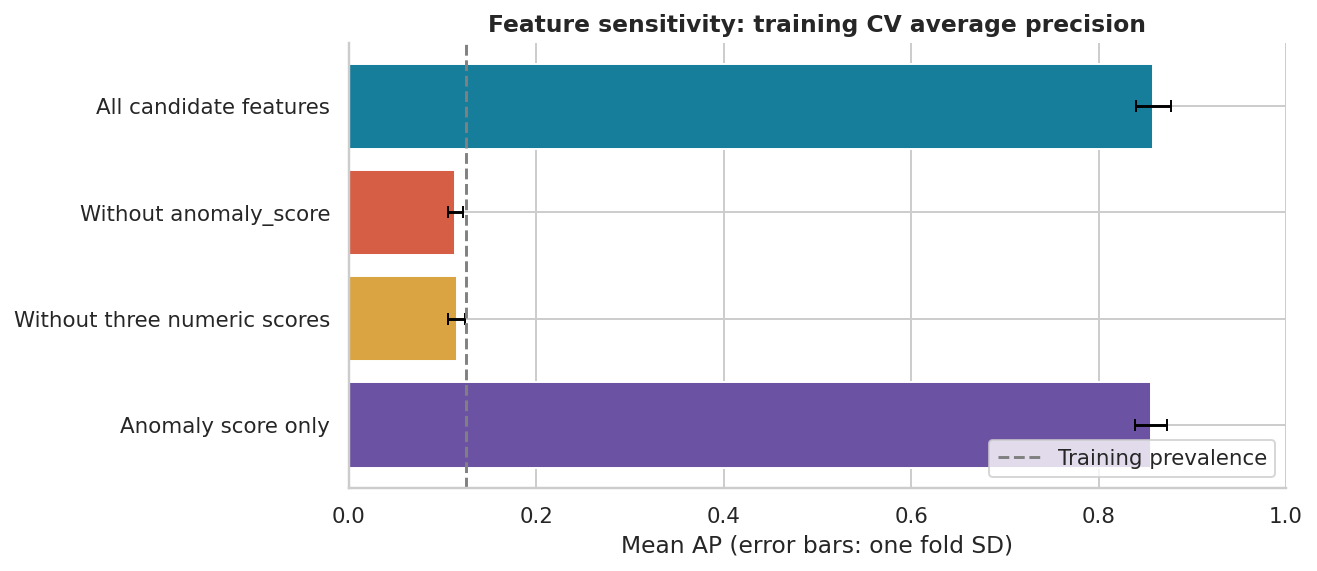

In [13]:
numeric_score_columns = {'anomaly_score', 'device_risk_score', 'transaction_velocity_score'}
ablation_specs = {
    'All candidate features': FEATURE_COLUMNS,
    'Without anomaly_score': [c for c in FEATURE_COLUMNS if c != 'anomaly_score'],
    'Without three numeric scores': [c for c in FEATURE_COLUMNS if c not in numeric_score_columns],
    'Anomaly score only': ['anomaly_score']
}
ablation_rows = []
for label, columns in ablation_specs.items():
    if label == 'All candidate features':
        scores = np.asarray(final_cv_scores)
        probabilities = valid_probabilities
    else:
        diagnostic_model = clone(final_model)
        with threadpool_limits(limits=2):
            result = cross_validate(diagnostic_model, X_train[columns], y_train, cv=cv_splits,
                                    scoring='average_precision', n_jobs=1, error_score='raise')
            diagnostic_model.fit(X_train[columns], y_train)
        scores = result['test_score']
        probabilities = diagnostic_model.predict_proba(X_valid[columns])[:, 1]
    ablation_rows.append({'feature_set': label, 'raw_features': len(columns),
                         'cv_ap_mean': scores.mean(), 'cv_ap_sd': scores.std(ddof=1),
                         'validation_ap': average_precision_score(y_valid, probabilities),
                         'validation_roc_auc': roc_auc_score(y_valid, probabilities)})
ablation_results = pd.DataFrame(ablation_rows)
display(ablation_results)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.barh(ablation_results['feature_set'], ablation_results['cv_ap_mean'],
        xerr=ablation_results['cv_ap_sd'], color=['#167D9A', '#D55E45', '#D9A441', '#6C52A3'], capsize=3)
ax.axvline(y_train.mean(), color='gray', linestyle='--', label='Training prevalence')
ax.set(title='Feature sensitivity: training CV average precision', xlabel='Mean AP (error bars: one fold SD)', xlim=(0, 1))
ax.invert_yaxis()
ax.legend(loc='lower right')
show_figure(fig)


### What the fitted model relies on

Permutation importance measures the drop in validation AP when one raw feature is shuffled. Shuffling occurs before the feature pipeline, so engineered derivatives are recalculated consistently. Repeats indicate permutation variability, not confidence intervals. Correlated or substitutable features can share or hide importance, and a negative value can arise from sampling noise. These are predictive associations, not causal effects or proof of appropriate feature availability. The test partition is still unused for predictions.


,feature,mean_ap_drop,permutation_sd
4,anomaly_score,0.6948,0.0087
0,transaction_amount,0.0054,0.0015
2,device_risk_score,0.0038,0.0022
17,suspicious_ip_flag,0.0017,0.0015
6,transaction_time_hour,0.0014,0.0012
8,avg_monthly_balance,0.0009,0.0009
3,transfer_frequency,0.0008,0.0013
1,login_attempts,0.0004,0.0002
12,transaction_velocity_score,0.0004,0.0003
15,card_present_flag,0.0003,0.0003


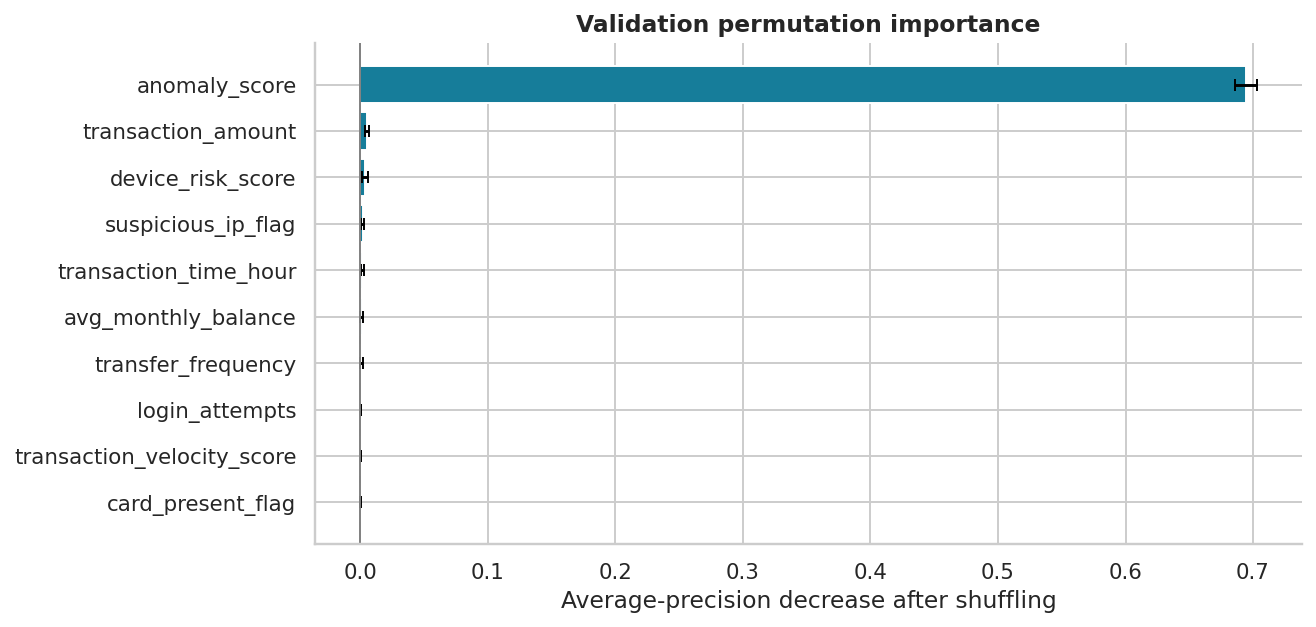

In [14]:
with threadpool_limits(limits=2):
    perm = permutation_importance(final_model, X_valid, y_valid, scoring='average_precision',
                                  n_repeats=5, random_state=SEED + 4, n_jobs=1)
importance_results = pd.DataFrame({'feature': FEATURE_COLUMNS, 'mean_ap_drop': perm.importances_mean,
                                   'permutation_sd': perm.importances_std}).sort_values('mean_ap_drop', ascending=False)
display(importance_results.head(10))
top_importance = importance_results.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.barh(top_importance['feature'], top_importance['mean_ap_drop'], xerr=top_importance['permutation_sd'],
        color='#167D9A', capsize=3)
ax.axvline(0, color='gray', linewidth=1)
ax.set(title='Validation permutation importance', xlabel='Average-precision decrease after shuffling')
show_figure(fig)


### Interpretation of the feature sensitivity checks

Removing `anomaly_score` reduces mean CV AP from **0.8582** to **0.1137**. Removing all three numeric scores gives **0.1152**. Both are near or below the training fraud prevalence of **12.52%**. At these fixed model settings, the remaining features have no demonstrated useful ranking advantage over a prevalence-only baseline. This does not establish that every possible model on those features would fail.

The anomaly-only diagnostic achieves CV AP **0.8561**, close to the full model's **0.8582**; on validation it scores **0.8234**, compared with **0.8202** for the full model. Thus the larger feature set has little demonstrated incremental value in this experiment. Permuting `anomaly_score` reduces validation AP by about **0.695**, much more than any other individual feature.

The main structural weakness is dependence on an unverified upstream signal. If that score was computed from the fraud outcome, from future records, or by fitting an upstream supervised model on all rows, a fold-safe downstream pipeline would still give an invalid prospective estimate. If it was produced independently and was available before review, this dependence may be legitimate. Establishing which case applies requires source lineage, not a statistical guess. Removing the three scores also leaves aggregate timing and `suspicious_ip_flag` unresolved. These diagnostic results do not change the already selected final model; they define the limits of its interpretation and a future comparison to a simpler score-only system.


## Part 4. Final evaluation and analytical depth

### Freeze the decision, then evaluate the test partition

The final pipeline is already fitted on the 60% training partition. Hyperparameters and augmentation came from training CV; the threshold came from validation. **Do not refit the model on train + validation here:** that would change its score scale after threshold selection. A future larger refit would need a new out-of-fold calibration/threshold procedure and separate evaluation.

Generate the final test predictions once below. Subsequent confusion matrices, intervals and error tables reuse those same frozen predictions. They are diagnostic outputs, not opportunities to change the threshold or select another model. Training metrics are measured on the original, unresampled training rows. Validation threshold metrics are selection-biased because validation chose that threshold; the test metrics estimate its transfer.


In [15]:
frozen_decision = {'model': final_name, 'threshold': final_threshold,
                   'selected_parameters': searches[baseline_name].best_params_,
                   'fit_partition': 'training only', 'seed': SEED, 'input_sha256': file_sha256}
print(json.dumps(frozen_decision, indent=2))

# First and only prediction of the final model on the test partition.
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= final_threshold).astype(int)
train_probabilities = final_model.predict_proba(X_train)[:, 1]
dummy_test_probabilities = dummy_model.predict_proba(X_test)[:, 1]

evaluation_results = pd.DataFrame({
    'Training (in sample)': evaluate_scores(y_train, train_probabilities, final_threshold),
    'Validation (threshold selected here)': evaluate_scores(y_valid, valid_probabilities, final_threshold),
    'Test (held out)': evaluate_scores(y_test, test_probabilities, final_threshold),
    'Dummy test (threshold 0.5)': evaluate_scores(y_test, dummy_test_probabilities, 0.5)
}).T
metric_order = ['accuracy', 'precision', 'recall', 'f1', 'f2', 'roc_auc',
                'average_precision', 'pr_auc_trapezoid', 'brier', 'alert_rate']
display(evaluation_results[metric_order].T)
display(evaluation_results[['tn', 'fp', 'fn', 'tp']].astype(int))
test_metrics = evaluate_scores(y_test, test_probabilities, final_threshold)
display(pd.DataFrame(classification_report(y_test, test_predictions, labels=[0, 1],
        target_names=['Nonfraud', 'Fraud'], zero_division=0, output_dict=True)).T)


{
  "model": "Logistic regression (no oversampling)",
  "threshold": 0.20859418413075956,
  "selected_parameters": {
    "model__C": 0.1
  },
  "fit_partition": "training only",
  "seed": 2026,
  "input_sha256": "7bbd26f45405c50c259e3ee719863eb599a950a6a449efc8286ec99d74e70141"
}


,Training (in sample),Validation (threshold selected here),Test (held out),Dummy test (threshold 0.5)
accuracy,0.9338,0.9380,0.9505,0.8750
precision,0.6777,0.6921,0.7525,0.0000
recall,0.8988,0.9080,0.9000,0.0000
f1,0.7728,0.7855,0.8197,0.0000
f2,0.8438,0.8547,0.8661,0.0000
roc_auc,0.9782,0.9714,0.9813,0.5000
average_precision,0.8654,0.8202,0.9023,0.1250
pr_auc_trapezoid,0.8653,0.8194,0.9021,0.5625
brier,0.0377,0.0412,0.0325,0.1094
alert_rate,0.1660,0.1640,0.1495,0.0000


,tn,fp,fn,tp
Training (in sample),4928,321,76,675
Validation (threshold selected here),1649,101,23,227
Test (held out),1676,74,25,225
Dummy test (threshold 0.5),1750,0,250,0


,precision,recall,f1-score,support
Nonfraud,0.9853,0.9577,0.9713,"1,750.0000"
Fraud,0.7525,0.9000,0.8197,250.0000
accuracy,0.9505,0.9505,0.9505,0.9505
macro avg,0.8689,0.9289,0.8955,"2,000.0000"
weighted avg,0.9562,0.9505,0.9524,"2,000.0000"


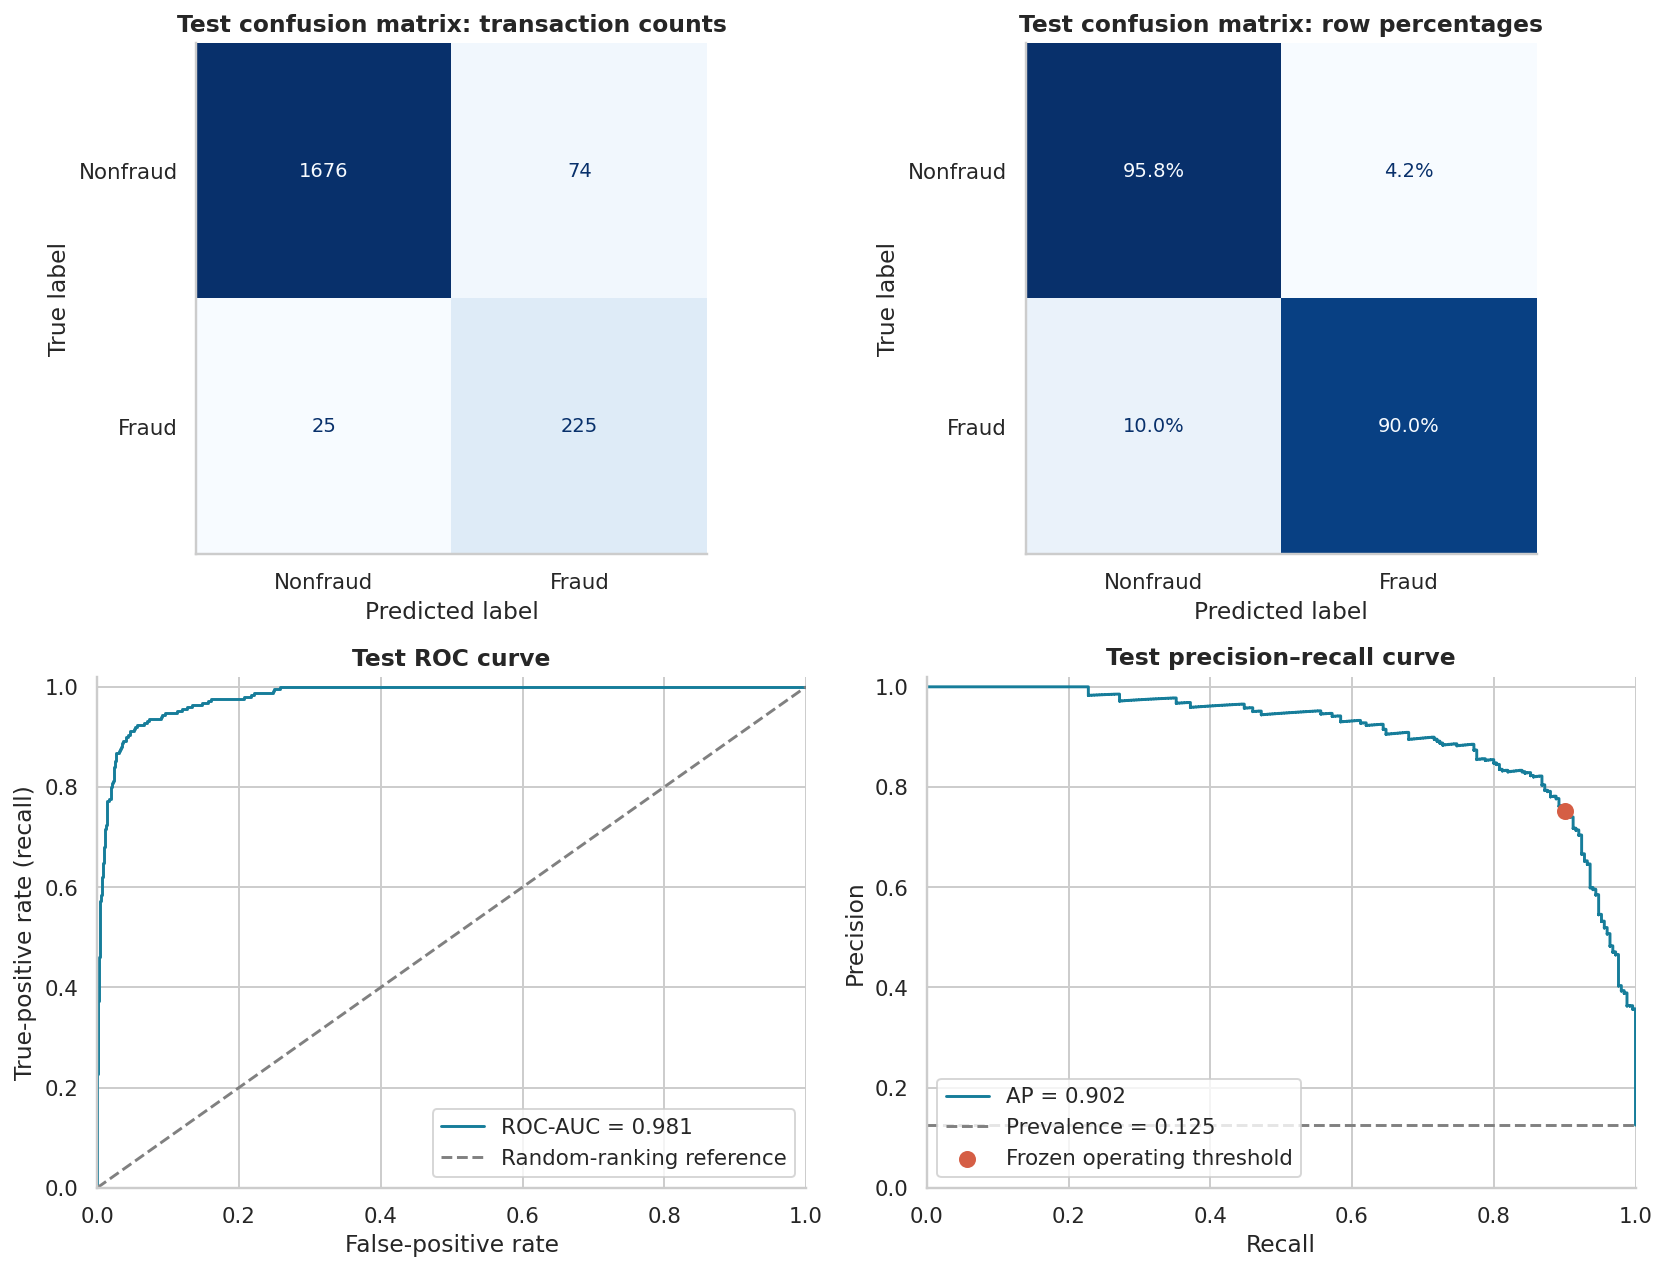

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9.2))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, labels=[0, 1],
    display_labels=['Nonfraud', 'Fraud'], values_format='d', colorbar=False, cmap='Blues', ax=axes[0, 0])
axes[0, 0].set_title('Test confusion matrix: transaction counts')
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, labels=[0, 1], normalize='true',
    display_labels=['Nonfraud', 'Fraud'], values_format='.1%', colorbar=False, cmap='Blues', ax=axes[0, 1])
axes[0, 1].set_title('Test confusion matrix: row percentages')
axes[0, 0].grid(False)
axes[0, 1].grid(False)

fpr, tpr, _ = roc_curve(y_test, test_probabilities)
axes[1, 0].plot(fpr, tpr, color='#167D9A', label=f'ROC-AUC = {test_metrics["roc_auc"]:.3f}')
axes[1, 0].plot([0, 1], [0, 1], '--', color='gray', label='Random-ranking reference')
axes[1, 0].set(title='Test ROC curve', xlabel='False-positive rate', ylabel='True-positive rate (recall)',
               xlim=(0, 1), ylim=(0, 1.02))
axes[1, 0].legend(loc='lower right')

precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_probabilities)
axes[1, 1].step(recall_curve, precision_curve, where='post', color='#167D9A',
               label=f'AP = {test_metrics["average_precision"]:.3f}')
axes[1, 1].axhline(y_test.mean(), linestyle='--', color='gray', label=f'Prevalence = {y_test.mean():.3f}')
axes[1, 1].scatter(test_metrics['recall'], test_metrics['precision'], color='#D55E45', s=60,
                  label='Frozen operating threshold', zorder=3)
axes[1, 1].set(title='Test precision–recall curve', xlabel='Recall', ylabel='Precision',
               xlim=(0, 1), ylim=(0, 1.02))
axes[1, 1].legend(loc='lower left')
show_figure(fig)


### What the held-out results mean

At the frozen threshold, the model catches **225 of 250** fraud cases (**90.0% recall**) and misses **25**. It sends **74** nonfraud transactions for review and correctly leaves **1,676** unflagged. Of the **299** alerts, **75.25%** are labelled fraud; **24.75%** are false alerts. The alert rate is **14.95%** of transactions, and the false-positive rate among nonfraud records is **4.23%**. These workload figures describe this held-out sample; capacity or monetary loss cannot be inferred without operational inputs.

Test F1 is **0.8197**, F2 **0.8661**, ROC-AUC **0.9813**, and AP **0.9023**. The majority dummy has **87.5% accuracy** and **zero fraud recall**, demonstrating why accuracy alone would be an inadequate objective. The final model's **95.05% accuracy** is useful context, not the basis of selection.

Full-training AP is **0.8654**, validation AP **0.8202**, and test AP **0.9023**. The higher test result is a favorable sample realization, not evidence that the model learned after training or that it will improve in deployment. The CV variability, validation/test difference and restricted split design argue for qualified generalization claims. The bootstrap intervals below quantify sampling uncertainty conditional on this test cohort and fitted model.

**Why the dummy's trapezoidal PR-AUC is 0.5625:** a constant score supplies only a coarse precision–recall path, including the conventional no-positive-prediction endpoint at precision 1 and recall 0. Connecting these points linearly yields an inflated trapezoidal area despite no discrimination. Its AP is correctly **0.125**, equal to test prevalence, and its ROC-AUC is **0.5**. This is why AP is the primary ranking metric and trapezoidal PR-AUC is reported separately rather than used to choose a model.


### Robustness and uncertainty

The fold table describes training split sensitivity, and the validation threshold plot shows how operating behavior changes around the chosen cutoff. Add a **stratified bootstrap of the frozen test predictions**: resample fraud rows and nonfraud rows separately with replacement, retaining the observed test prevalence, and take 2.5th/97.5th percentiles.

These are approximate, conditional intervals for this fitted model on an exchangeable transaction sample. They do not include uncertainty from model selection, label errors, unknown customer clusters, future drift or a different deployment prevalence. The bootstrap refits no model and chooses no threshold. AP and precision can change substantially if the deployment fraud prevalence differs.


In [17]:
bootstrap_rng = np.random.default_rng(SEED + 5)
y_test_array = y_test.to_numpy()
class_positions = [np.flatnonzero(y_test_array == label) for label in [0, 1]]
bootstrap_rows = []
for _ in range(N_BOOTSTRAPS):
    sampled = np.concatenate([bootstrap_rng.choice(pos, size=len(pos), replace=True) for pos in class_positions])
    yt, pt = y_test_array[sampled], test_probabilities[sampled]
    pred = (pt >= final_threshold).astype(int)
    tp = int(np.sum((yt == 1) & (pred == 1)))
    fp = int(np.sum((yt == 0) & (pred == 1)))
    fn = int(np.sum((yt == 1) & (pred == 0)))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    bootstrap_rows.append({'average_precision': average_precision_score(yt, pt),
                           'roc_auc': roc_auc_score(yt, pt), 'precision': precision, 'recall': recall,
                           'f1': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
                           'f2': 5 * tp / (5 * tp + fp + 4 * fn) if 5 * tp + fp + 4 * fn else 0.0})
bootstrap_samples = pd.DataFrame(bootstrap_rows)
confidence_intervals = pd.DataFrame({
    'estimate': pd.Series({key: test_metrics[key] for key in bootstrap_samples.columns}),
    'lower_95': bootstrap_samples.quantile(0.025),
    'upper_95': bootstrap_samples.quantile(0.975)
})
display(confidence_intervals)


,estimate,lower_95,upper_95
average_precision,0.9023,0.8740,0.9303
roc_auc,0.9813,0.9750,0.9869
precision,0.7525,0.7112,0.7965
recall,0.9000,0.8640,0.9360
f1,0.8197,0.7890,0.8519
f2,0.8661,0.8346,0.8970


### Error analysis: missed fraud and unnecessary alerts

A false negative is labelled fraud that the model does not flag. A false positive is a nonfraud transaction sent for review. We examine both, rather than reporting only overall accuracy. Group tables include denominators: recall is TP / fraud count, and false-positive rate is FP / nonfraud count. Differences across small groups are descriptive and do not establish discrimination, causality or statistical significance.

Amount bands use quartile boundaries learned from **training amounts only**. Example transactions are chosen by confidence among actual errors, not to imply that their observed attributes caused the error. These test diagnostics do not feed back into this model's design; any proposed change requires a new evaluation set.


In [18]:
error_analysis = df.loc[test_index, [ID_COLUMN, 'transaction_amount', 'payment_channel',
                                   'authentication_type', 'international_transaction_flag', 'anomaly_score']].copy()
error_analysis['actual_fraud'] = y_test.to_numpy()
error_analysis['fraud_score'] = test_probabilities
error_analysis['predicted_fraud'] = test_predictions
error_analysis['outcome'] = np.select([
    (error_analysis.actual_fraud == 1) & (error_analysis.predicted_fraud == 1),
    (error_analysis.actual_fraud == 1) & (error_analysis.predicted_fraud == 0),
    (error_analysis.actual_fraud == 0) & (error_analysis.predicted_fraud == 1)
], ['TP', 'FN', 'FP'], default='TN')
amount_cutpoints = X_train['transaction_amount'].quantile([0.25, 0.50, 0.75]).to_numpy()
error_analysis['amount_band'] = pd.cut(error_analysis['transaction_amount'],
    bins=[-np.inf, *amount_cutpoints, np.inf], labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])

def error_summary_by(column):
    records = []
    for group, subset in error_analysis.groupby(column, observed=True, dropna=False):
        fraud = int(subset.actual_fraud.sum())
        nonfraud = len(subset) - fraud
        tp, fp, fn = [int((subset.outcome == outcome).sum()) for outcome in ['TP', 'FP', 'FN']]
        records.append({column: group, 'transactions': len(subset), 'fraud': fraud, 'nonfraud': nonfraud,
                        'tp': tp, 'fn': fn, 'fp': fp,
                        'recall': tp / fraud if fraud else np.nan,
                        'false_positive_rate': fp / nonfraud if nonfraud else np.nan,
                        'alert_precision': tp / (tp + fp) if tp + fp else np.nan})
    return pd.DataFrame(records).set_index(column)

group_error_tables = {}
for column in ['payment_channel', 'international_transaction_flag', 'amount_band']:
    print(f'Error analysis by {column}')
    group_error_tables[column] = error_summary_by(column)
    display(group_error_tables[column])
print('Training amount quartile boundaries (source units):', np.round(amount_cutpoints, 2))

display(error_analysis.groupby('outcome')['anomaly_score'].agg(['count', 'mean', 'median', 'min', 'max']))


Error analysis by payment_channel


,transactions,fraud,nonfraud,tp,fn,fp,recall,false_positive_rate,alert_precision
payment_channel,,,,,,,,,
ATM,149,23,126,18,5,3,0.7826,0.0238,0.8571
Mobile App,958,114,844,104,10,38,0.9123,0.0450,0.7324
POS Terminal,216,27,189,22,5,6,0.8148,0.0317,0.7857
Web Banking,677,86,591,81,5,27,0.9419,0.0457,0.7500


Error analysis by international_transaction_flag


,transactions,fraud,nonfraud,tp,fn,fp,recall,false_positive_rate,alert_precision
international_transaction_flag,,,,,,,,,
0,1015,138,877,125,13,52,0.9058,0.0593,0.7062
1,985,112,873,100,12,22,0.8929,0.0252,0.8197


Error analysis by amount_band


,transactions,fraud,nonfraud,tp,fn,fp,recall,false_positive_rate,alert_precision
amount_band,,,,,,,,,
Q1 (lowest),520,66,454,60,6,23,0.9091,0.0507,0.7229
Q2,502,62,440,56,6,20,0.9032,0.0455,0.7368
Q3,507,56,451,49,7,14,0.8750,0.0310,0.7778
Q4 (highest),471,66,405,60,6,17,0.9091,0.0420,0.7792


Training amount quartile boundaries (source units): [ 6211.73 12319.93 18767.76]


,count,mean,median,min,max
outcome,,,,,
FN,25,0.5012,0.5200,0.3900,0.6000
FP,74,0.6655,0.6450,0.5700,0.8400
TN,1676,0.2659,0.2700,0.0100,0.6000
TP,225,0.8068,0.8100,0.5800,0.9900


Up to five most confident false negatives (lowest predicted fraud scores):


,transaction_id,transaction_amount,payment_channel,anomaly_score,actual_fraud,fraud_score,predicted_fraud,outcome
6696,1006697,"10,540.3800",ATM,0.3900,1,0.0210,0,FN
6423,1006424,"22,791.2800",ATM,0.4000,1,0.0226,0,FN
9984,1009985,"5,398.0900",Web Banking,0.4200,1,0.0232,0,FN
4292,1004293,"7,165.4900",Mobile App,0.4300,1,0.0294,0,FN
2383,1002384,"10,604.9300",Web Banking,0.4300,1,0.0304,0,FN


Up to five most confident false positives (highest predicted fraud scores):


,transaction_id,transaction_amount,payment_channel,anomaly_score,actual_fraud,fraud_score,predicted_fraud,outcome
2629,1002630,"24,608.0700",Mobile App,0.8400,0,0.9356,1,FP
5724,1005725,"15,924.5500",Web Banking,0.8400,0,0.9185,1,FP
6705,1006706,"14,588.9100",Mobile App,0.8100,0,0.8821,1,FP
2362,1002363,"19,796.1700",Web Banking,0.8200,0,0.8692,1,FP
1441,1001442,"20,661.6400",POS Terminal,0.8200,0,0.8436,1,FP


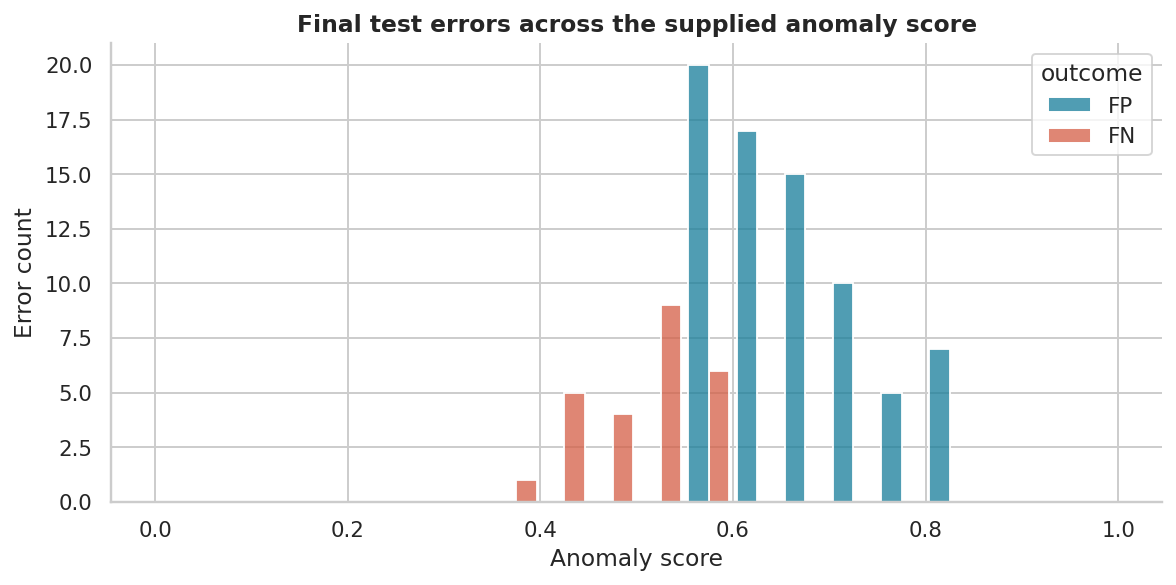

In [19]:
error_columns = [ID_COLUMN, 'transaction_amount', 'payment_channel', 'anomaly_score',
                 'actual_fraud', 'fraud_score', 'predicted_fraud', 'outcome']
print('Up to five most confident false negatives (lowest predicted fraud scores):')
display(error_analysis.loc[error_analysis.outcome == 'FN', error_columns].nsmallest(5, 'fraud_score'))
print('Up to five most confident false positives (highest predicted fraud scores):')
display(error_analysis.loc[error_analysis.outcome == 'FP', error_columns].nlargest(5, 'fraud_score'))

fig, ax = plt.subplots(figsize=(8.5, 4.3))
sns.histplot(data=error_analysis.loc[error_analysis.outcome.isin(['FP', 'FN'])], x='anomaly_score',
             hue='outcome', bins=np.linspace(0, 1, 21), multiple='dodge', shrink=0.85, ax=ax)
ax.set(title='Final test errors across the supplied anomaly score', xlabel='Anomaly score', ylabel='Error count')
show_figure(fig)


### What the errors reveal

False negatives have a median anomaly score of **0.520**, compared with **0.810** for detected fraud. False positives have median **0.645**, compared with **0.270** for correctly unflagged nonfraud. The model therefore tends to miss labelled fraud with less suspicious upstream scores and flag nonfraud with higher scores. These are associations from the frozen predictions; the data cannot tell us whether they reflect unusual fraud, upstream-score error or label error.

The channel table identifies a useful follow-up question. ATM recall is **18/23 (78.3%)**, compared with **81/86 (94.2%)** for Web Banking; POS Terminal recall is **22/27 (81.5%)**. The ATM and POS denominators are small, so these differences need more independent observations before operational conclusions. Mobile App produces the largest false-positive count (**38**), but it also has the largest test volume. Its false-positive rate is approximately **4.50%**, close to Web Banking's **4.57%**; raw counts alone would give a misleading comparison.

Reducing the threshold could recover some missed fraud while increasing investigation burden, as the validation sensitivity plot shows. A better next experiment would audit disputed labels and seek correctly timed features that separate the overlapping score ranges. We do not modify this model in response to the test error examples. Any such revision must be evaluated on newly held-out data.


### Reuse the fitted decision rule

The function below accepts the original 18 predictor columns, applies the fitted pipeline and uses the frozen validation-selected threshold. The demonstration uses validation records. Its output is a review flag and model score, not a guaranteed fraud determination or a claim of probability calibration. Running this notebook creates the fitted model in memory; rerun the cells to reproduce it in a fresh session.


In [20]:
def score_transactions(new_transactions):
    absent = sorted(set(FEATURE_COLUMNS) - set(new_transactions.columns))
    if absent:
        raise ValueError(f'Missing predictor columns: {absent}')
    probabilities = final_model.predict_proba(new_transactions[FEATURE_COLUMNS])[:, 1]
    return pd.DataFrame({'fraud_score': probabilities,
                         'review_flag': (probabilities >= final_threshold).astype(int)},
                        index=new_transactions.index)

display(score_transactions(X_valid.head(5)))
assert len(test_probabilities) == len(X_test) and np.isfinite(test_probabilities).all()
assert 0 <= final_threshold <= 1
assert test_metrics['tn'] + test_metrics['fp'] + test_metrics['fn'] + test_metrics['tp'] == len(X_test)

# Compact record for reproducing and interpreting this executed run.
run_summary = {
    'rows': len(df), 'columns': df.shape[1], 'fraud_count': int(df[TARGET].sum()),
    'fraud_rate': float(df[TARGET].mean()), 'missing_values': int(df[FEATURE_COLUMNS].isna().sum().sum()),
    'duplicate_rows': duplicate_rows, 'sha256': file_sha256, 'versions': versions,
    'split_summary': split_summary.reset_index().to_dict('records'),
    'baseline_family': baseline_name, 'final_name': final_name, 'threshold': final_threshold,
    'parameters': searches[baseline_name].best_params_,
    'cv_ap_mean': float(np.mean(final_cv_scores)), 'cv_ap_sd': float(np.std(final_cv_scores, ddof=1)),
    'augmentation_retained': bool(use_oversampling), 'augmentation_ap_delta': augmentation_delta,
    'augmentation_fold_results': augmentation_fold_results.to_dict('records'),
    'augmentation_validation': augmentation_validation.to_dict('records'),
    'tuning_results': tuning_results.to_dict('records'),
    'evaluation': evaluation_results.to_dict('index'), 'test_metrics': test_metrics,
    'confidence_intervals': confidence_intervals.to_dict('index'),
    'ablations': ablation_results.to_dict('records'),
    'importance': importance_results.to_dict('records'),
    'train_anomaly_correlation': float(train_correlations['anomaly_score']),
    'channel_errors': group_error_tables['payment_channel'].reset_index().to_dict('records'),
    'outcome_anomaly': error_analysis.groupby('outcome')['anomaly_score'].agg(['mean', 'median']).to_dict('index'),
    'elapsed_seconds': time.perf_counter() - RUN_STARTED
}
print(f'Completed all analysis cells in {run_summary["elapsed_seconds"]:.1f} seconds in this runtime.')
print('Model, preprocessing, augmentation policy and threshold were held fixed for test evaluation.')


,fraud_score,review_flag
3774,0.0148,0
8467,0.0244,0
4101,0.0843,0
8711,0.0008,0
5738,0.8541,1


Completed all analysis cells in 73.2 seconds in this runtime.
Model, preprocessing, augmentation policy and threshold were held fixed for test evaluation.


### Sources and reproducibility notes

- **Assignment requirements:** supplied `Group Assignment 2-MS4.pdf`, pages 1–3. The notebook follows the five required parts and the notebook-only submission format.
- **Data:** supplied `banking_transactions.csv`; the file's SHA-256 is printed and checked near the top. All reported counts, tables and experimental results are computed from that file. Source attribution: [Deepesh Kansotia's Kaggle dataset](https://www.kaggle.com/datasets/deepeshkansotia/banking-fraud-detection-and-risk-analytics-dataset/data). Unverified collection, labeling and feature-generation details are treated as limitations.
- **Leakage prevention:** [scikit-learn, Common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html).
- **Metric definition:** [scikit-learn, `average_precision_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
- **Operating threshold:** [scikit-learn, Tuning the decision threshold](https://scikit-learn.org/stable/modules/classification_threshold.html).
- **Sampling method:** [imbalanced-learn, Over-sampling](https://imbalanced-learn.org/stable/over_sampling.html). This notebook implements the simple duplication method directly; it does not require imbalanced-learn.

Documentation consulted 13 November 2026. Library versions are printed by the setup cell. Random seeds, split fractions, fold count, parameter grids and the selection policy are explicit. Small numerical or timing differences can occur in other environments. The following reflection describes the saved run and should be updated if the experiment is changed.


## Part 5. Analytical reflection

### Generalization

The selected logistic regression (`C=0.1`, without oversampling) achieved mean training CV AP of **0.858**, with fold SD **0.019**. Its in-sample AP was **0.865**, validation AP **0.820**, and test AP **0.902**. Test ROC-AUC was **0.981**, recall **90.0%**, and precision **75.3%**. The modest training-to-CV gap provides limited evidence against severe overfitting within this sample. However, the favourable test-versus-validation difference does not prove stronger deployment generalization; different transaction composition and sampling variation can produce this ordering. The test AP bootstrap interval, **0.874–0.930**, is conditional on the fitted model and observed prevalence. It excludes model-selection uncertainty, customer dependence, label errors and future distribution changes.

### Structural weaknesses

Performance depends heavily on the supplied `anomaly_score`. Removing it reduced CV AP from **0.858** to **0.114**, near the **0.125** fraud prevalence, while using it alone achieved **0.856**. At these fixed settings, the remaining inputs add little demonstrated ranking value. This does not prove they are universally uninformative, nor establish that the anomaly score contains leaked labels. Its unverified origin is nevertheless a central limitation: this model may chiefly reproduce an upstream detector. Missing customer identifiers prevent account-disjoint evaluation, and the absence of full timestamps prevents a chronological test. The random split therefore establishes only conditional performance on comparable transactions from this file.

### Deployment risks

The validation-selected threshold, **0.2086**, maximizes F2 under an assumed preference for recall. It does not represent a known economic loss function. On 2,000 test transactions, the model flags **299 (14.95%)**, including **74 false positives**, and misses **25 fraudulent transactions**. Whether this workload and residual risk are acceptable depends on investigation capacity and actual losses. Historical aggregates must be computed as of each transaction, and session duration may only become available after the session ends. Even retrospective use requires verified feature lineage. Payment-channel differences warrant investigation, but small subgroup counts cannot establish systematic disparities or justify channel-specific thresholds from this test set.

### Augmentation

Random oversampling reduced mean matched-fold CV AP by **0.00273**, failing the predeclared improvement requirement. After separately selecting validation thresholds, augmented and original F2 were nearly identical: **0.856 versus 0.855**, both with **90.8% recall**. Thus, the large recall improvement at the default 0.5 threshold mainly reflects a changed operating point, not demonstrated improvement in ranking. Validation Brier score also worsened from **0.0412 to 0.0618**. Retaining the unaugmented model is justified by the development evidence, although this controlled experiment does not exclude benefits from other sampling ratios or separately optimized models. Duplicating minority cases adds no independent information and can amplify erroneous labels or memorization.

### Technically grounded future improvements

First, document how fraud labels and upstream scores were generated, including whether their producers had access to evaluation labels. Verify that every historical feature excludes later transactions. Recover account identifiers and timestamps, then evaluate on later periods and unseen accounts before claiming prospective generalization. Compare the compact anomaly-only model with the full model on fresh evaluation data, accounting for parameter-selection uncertainty. Define review costs and capacity before choosing a production threshold; assess calibration on independent development observations at realistic prevalence. Investigate missed fraud and collect additional independently labelled examples of underrepresented mechanisms. These steps address the observed information and evaluation limitations more directly than expanding the model search. Because the present test results have now been inspected, proposed changes require a new untouched evaluation set.
